In [23]:
# Cell 1: Import all libraries used in this session
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import (mean_absolute_error, mean_squared_error, r2_score,
                             accuracy_score, precision_score, recall_score,
                             f1_score, confusion_matrix, ConfusionMatrixDisplay)

sns.set_theme(style="whitegrid")
print("All libraries imported successfully.")

All libraries imported successfully.


In [24]:
import numpy as np
import pandas as pd

rng = np.random.default_rng(42)  # fixed seed -> same data for everyone
n = 200

size_sqft = rng.integers(500, 3000, n).astype(float)  # house size
bedrooms = np.clip((size_sqft / 700 + rng.integers(-1, 2, n)).round(), 1, 5).astype(int)
age_years = rng.integers(0, 40, n).astype(float)  # house age
location = rng.choice(["Urban", "Suburban", "Rural"], n, p=[0.4, 0.4, 0.2])
loc_bonus = pd.Series(location).map({"Urban": 15, "Suburban": 5, "Rural": 0}).to_numpy()

# Price in lakhs: depends on size, bedrooms, age, location + random noise
price_lakhs = (
    10
    + 0.05 * size_sqft
    + 4 * bedrooms
    - 0.4 * age_years
    + loc_bonus
    + rng.normal(0, 8, n)
).round(2)

df = pd.DataFrame(
    {
        "size_sqft": size_sqft,
        "bedrooms": bedrooms,
        "age_years": age_years,
        "location": location,
        "price_lakhs": price_lakhs,
    }
)

# Make the data messy on purpose (like real life)
df = pd.concat([df, df.iloc[:3]], ignore_index=True)  # 3 duplicate rows
df.loc[rng.choice(np.arange(10, n), 8, replace=False), "size_sqft"] = (
    np.nan  # 8 missing sizes
)
df.loc[rng.choice(np.arange(10, n), 10, replace=False), "age_years"] = (
    np.nan  # 10 missing ages
)

print("Dataset created. Target column = 'price_lakhs'")
df.head()

Dataset created. Target column = 'price_lakhs'


,size_sqft,bedrooms,age_years,location,price_lakhs
0,723.0,1,39.0,Suburban,51.02
1,2434.0,4,31.0,Urban,151.03
2,2136.0,3,12.0,Suburban,133.65
3,1597.0,3,38.0,Suburban,91.20
4,1582.0,2,19.0,Rural,88.14


In [25]:
# Cell 3: First look at the data
print("Shape (rows, columns):", df.shape)
print("\n--- Data types and non-null counts ---")
df.info()
print("\n--- Summary statistics (numeric columns) ---")
df.describe()

Shape (rows, columns): (203, 5)

--- Data types and non-null counts ---
<class 'pandas.DataFrame'>
RangeIndex: 203 entries, 0 to 202
Data columns (total 5 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   size_sqft    195 non-null    float64
 1   bedrooms     203 non-null    int64  
 2   age_years    193 non-null    float64
 3   location     203 non-null    str    
 4   price_lakhs  203 non-null    float64
dtypes: float64(3), int64(1), str(1)
memory usage: 9.3 KB

--- Summary statistics (numeric columns) ---


,size_sqft,bedrooms,age_years,price_lakhs
count,195.000000,203.000000,193.000000,203.000000
mean,1777.835897,2.532020,19.854922,107.911921
std,692.581004,1.170051,12.218057,39.151901
min,518.000000,1.000000,0.000000,34.100000
25%,1211.500000,2.000000,9.000000,74.960000
50%,1762.000000,2.000000,20.000000,106.160000
75%,2407.000000,3.000000,32.000000,140.960000
max,2990.000000,5.000000,39.000000,182.470000


In [26]:
# Cell 4: Check and fix data quality problems
print("Missing values per column:")
print(df.isnull().sum())

print("\nNumber of duplicate rows:", df.duplicated().sum())

df = df.drop_duplicates().reset_index(drop=True)   # remove duplicates
print("Shape after removing duplicates:", df.shape)

numerical_cols   = df.select_dtypes(include="number").columns.tolist()
categorical_cols = df.select_dtypes(include="object").columns.tolist()
print("\nNumerical columns :", numerical_cols)
print("Categorical columns:", categorical_cols)

Missing values per column:
size_sqft       8
bedrooms        0
age_years      10
location        0
price_lakhs     0
dtype: int64

Number of duplicate rows: 3
Shape after removing duplicates: (200, 5)

Numerical columns : ['size_sqft', 'bedrooms', 'age_years', 'price_lakhs']
Categorical columns: ['location']


C:\Users\varsh\AppData\Local\Temp\ipykernel_22388\3790401166.py:11: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_cols = df.select_dtypes(include="object").columns.tolist()


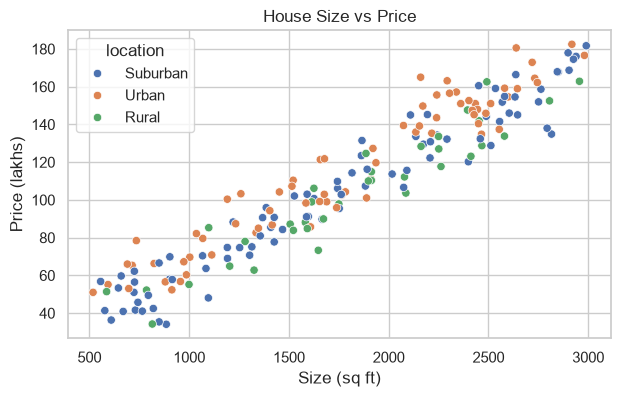

In [27]:
# Cell 5: Does bigger size mean higher price?
plt.figure(figsize=(7, 4))
sns.scatterplot(data=df, x="size_sqft", y="price_lakhs", hue="location")
plt.title("House Size vs Price")
plt.xlabel("Size (sq ft)")
plt.ylabel("Price (lakhs)")
plt.show()

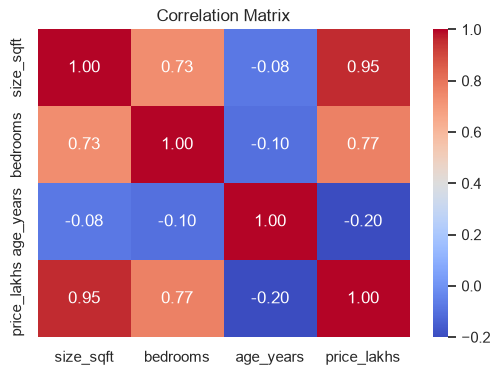

In [28]:
# Cell 6: Correlation matrix (numeric columns only)
plt.figure(figsize=(6, 4))
sns.heatmap(df.corr(numeric_only=True), annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Matrix")
plt.show()

In [29]:
# Cell 7: Separate features (X) and target (y), then split
X = df.drop(columns="price_lakhs")     # all columns except the target
y = df["price_lakhs"]                  # the target

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Training rows:", X_train.shape[0])
print("Testing rows :", X_test.shape[0])

Training rows: 160
Testing rows : 40


In [30]:
# Cell 8: Build a preprocessor and see what it does to the data
numeric_features     = ["size_sqft", "bedrooms", "age_years"]
categorical_features = ["location"]

numeric_steps = Pipeline([
    ("imputer", SimpleImputer(strategy="median"))        # fill missing numbers with median
])
categorical_steps = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),  # fill missing categories
    ("onehot", OneHotEncoder(handle_unknown="ignore"))     # words -> 0/1 columns
])

preprocessor = ColumnTransformer([
    ("num", numeric_steps, numeric_features),
    ("cat", categorical_steps, categorical_features),
])

In [31]:
from sklearn.preprocessing import StandardScaler, MinMaxScaler, LabelEncoder, OneHotEncoder

# Cell 8: Build a preprocessor and see what it does to the data
numeric_features     = ["size_sqft", "bedrooms", "age_years"]
categorical_features = ["location"]

numeric_steps = Pipeline([
    ("imputer", SimpleImputer(strategy="median"))        # fill missing numbers with median
])
categorical_steps = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),  # fill missing categories
    ("onehot", OneHotEncoder(handle_unknown="ignore"))     # words -> 0/1 columns
])

preprocessor = ColumnTransformer([
    ("num", numeric_steps, numeric_features),
    ("cat", categorical_steps, categorical_features),
])
# Fit the preprocessor using training data only
preprocessor.fit(X_train)

# Transform training and testing data
X_train_ready = preprocessor.transform(X_train)
X_test_ready = preprocessor.transform(X_test)

# Compare shapes before and after preprocessing
print(
    "Train shape before:", X_train.shape,
    "-> after:", X_train_ready.shape
)

# Display feature names after processing
print("Feature names after processing:")
print(preprocessor.get_feature_names_out())

Train shape before: (160, 4) -> after: (160, 6)
Feature names after processing:
['num__size_sqft' 'num__bedrooms' 'num__age_years' 'cat__location_Rural'
 'cat__location_Suburban' 'cat__location_Urban']


In [32]:
# Cell 9: Leakage-safe thinking
# WRONG (leaks test information into training):
#   imputer.fit(X)                 # learns the median from ALL rows, including test rows
#
# RIGHT (what we did in Cell 8):
#   preprocessor.fit(X_train)      # learn only from training rows
#   preprocessor.transform(X_test) # just apply, never learn from test

#   preprocessor.transform(X_test) # just apply, never learn from test

train_median_size = X_train["size_sqft"].median()
full_median_size  = X["size_sqft"].median()
print("Median size learned from TRAIN only:", train_median_size)
print("Median size from ALL data (leaky)  :", full_median_size)
print("\nRule: split first, then fit preprocessing on training data only.")

Median size learned from TRAIN only: 1752.0
Median size from ALL data (leaky)  : 1757.0

Rule: split first, then fit preprocessing on training data only.


In [33]:
# Cell 10: Choose the 3 features and build a pipeline (imputer + model)
features = ["size_sqft", "bedrooms", "age_years"]

reg_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),   # fill missing values
    ("model", LinearRegression()),                   # the regression model
])

print("Features used:", features)
print("Target        : price_lakhs")

Features used: ['size_sqft', 'bedrooms', 'age_years']
Target        : price_lakhs


In [34]:
# Cell 11: Train (fit) the model using TRAINING data only
reg_pipeline.fit(X_train[features], y_train)
print("Model trained!")

Model trained!


In [35]:
# Cell 12: Look at what the model learned
model = reg_pipeline.named_steps["model"]

print("Intercept:", round(model.intercept_, 2))
coef_table = pd.DataFrame({"feature": features, "coefficient": model.coef_.round(3)})
print(coef_table)

Intercept: 17.35
     feature  coefficient
0  size_sqft        0.047
1   bedrooms        5.538
2  age_years       -0.375
